<a href="https://colab.research.google.com/github/souharached9-droid/classification-sons/blob/main/Classification_Sons_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import numpy as np
import pandas as pd
import librosa
import librosa.display
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
accuracy_score, classification_report, confusion_matrix
)

In [2]:
#importer dataset
!wget -q https://github.com/karoldvl/ESC-50/archive/refs/heads/master.zip -O esc50.zip
!unzip -q -o esc50.zip
DATASET_PATH = "/content/ESC-50-master"
AUDIO_PATH = os.path.join(DATASET_PATH, "audio")
CSV_PATH = os.path.join(DATASET_PATH, "meta", "esc50.csv")
metadata = pd.read_csv(CSV_PATH)
print(metadata.head())
print("Nombre total de fichiers :", len(metadata))
print("Nombre de classes :", metadata["category"].nunique())

            filename  fold  target        category  esc10  src_file take
0   1-100032-A-0.wav     1       0             dog   True    100032    A
1  1-100038-A-14.wav     1      14  chirping_birds  False    100038    A
2  1-100210-A-36.wav     1      36  vacuum_cleaner  False    100210    A
3  1-100210-B-36.wav     1      36  vacuum_cleaner  False    100210    B
4  1-101296-A-19.wav     1      19    thunderstorm  False    101296    A
Nombre total de fichiers : 2000
Nombre de classes : 50


In [3]:
# Commencer avec ESC-10
metadata_10 = metadata[metadata["esc10"] == True].copy()
print("Clips ESC-10 :", len(metadata_10))
print("Classes ESC-10 :", metadata_10["category"].nunique())
print(metadata_10["category"].value_counts())

Clips ESC-10 : 400
Classes ESC-10 : 10
category
dog               40
chainsaw          40
crackling_fire    40
helicopter        40
rain              40
crying_baby       40
clock_tick        40
sneezing          40
rooster           40
sea_waves         40
Name: count, dtype: int64


In [4]:

#Écouter un exemple
from IPython.display import Audio, display
sample = metadata_10.iloc[0]
path = os.path.join(AUDIO_PATH, sample["filename"])
signal, sr = librosa.load(path, sr=None, mono=True)
print("Fichier :", sample["filename"])
print("Classe :", sample["category"])
print("Fréquence :", sr, "Hz")
print("Durée :", len(signal) / sr, "secondes")
display(Audio(signal, rate=sr))

Fichier : 1-100032-A-0.wav
Classe : dog
Fréquence : 44100 Hz
Durée : 5.0 secondes


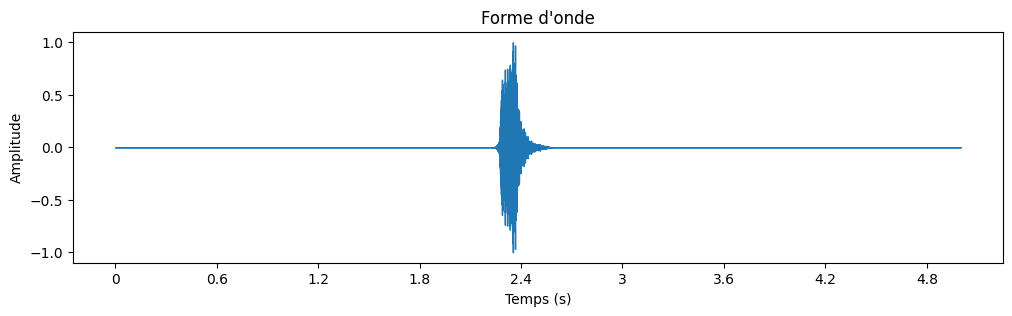

In [5]:

plt.figure(figsize=(12, 3))
librosa.display.waveshow(signal, sr=sr)
plt.title("Forme d'onde")
plt.xlabel("Temps (s)")
plt.ylabel("Amplitude")
plt.show()

In [6]:
#Afficher un spectrogramme
D = librosa.stft(signal)
S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

Nombre de sons ESC-10 : 400
Nombre de classes ESC-10 : 10


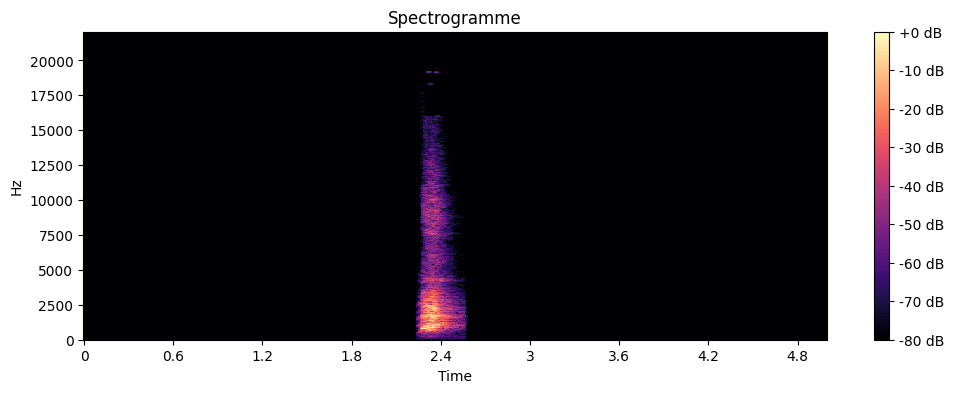

In [7]:
#sélectionner ESC-10
metadata_10 = metadata[metadata["esc10"] == True]

print("Nombre de sons ESC-10 :",
      len(metadata_10))

print("Nombre de classes ESC-10 :",
      metadata_10["category"].nunique())
plt.figure(figsize=(12, 4))
librosa.display.specshow(
S_db, sr=sr, x_axis="time", y_axis="hz"
)
plt.colorbar(format="%+2.0f dB")
plt.title("Spectrogramme")
plt.show()

In [8]:

TARGET_SR = 22050
DURATION = 5
TARGET_LENGTH = TARGET_SR * DURATION

def load_and_preprocess(file_path):

    # Charger en mono et rééchantillonner à 22 050 Hz
    y, sr = librosa.load(
        file_path,
        sr=TARGET_SR,
        mono=True
    )

    # Couper si le son est trop long
    # Compléter avec des zéros s'il est trop court
    if len(y) > TARGET_LENGTH:
        y = y[:TARGET_LENGTH]
    else:
        y = np.pad(
            y,
            (0, TARGET_LENGTH - len(y)),
            mode="constant"
        )

    # Normalisation de l'amplitude
    peak = np.max(np.abs(y))

    if peak > 0:
        y = y / peak

    return y


In [9]:
y = load_and_preprocess(path)
print("Nombre d'échantillons :", len(y))
print("Durée :", len(y) / TARGET_SR, "secondes")

Nombre d'échantillons : 110250
Durée : 5.0 secondes


In [10]:
def extract_mfcc_features(y, sr=TARGET_SR):

    mfcc = librosa.feature.mfcc(
        y=y,
        sr=sr,
        n_mfcc=40
    )

    delta = librosa.feature.delta(mfcc)
    delta2 = librosa.feature.delta(mfcc, order=2)

    features = np.concatenate([
        np.mean(mfcc, axis=1),
        np.std(mfcc, axis=1),
        np.mean(delta, axis=1),
        np.std(delta, axis=1),
        np.mean(delta2, axis=1),
        np.std(delta2, axis=1)
    ])

    return features

In [11]:
# Construire les données

X_mfcc = []
y_labels = []
folds = []

for _, row in metadata_10.iterrows():

    file_path = os.path.join(AUDIO_PATH, row["filename"])

    audio = load_and_preprocess(file_path)

    X_mfcc.append(extract_mfcc_features(audio))

    y_labels.append(row["category"])

    folds.append(row["fold"])


# Convertir les listes en tableaux NumPy

X_mfcc = np.array(X_mfcc)
y_labels = np.array(y_labels)
folds = np.array(folds)

# Afficher les dimensions

print("Forme de X :", X_mfcc.shape)
print("Forme des labels :", y_labels.shape)

Forme de X : (400, 240)
Forme des labels : (400,)


In [12]:
#Validation avec les folds ESC-50
from sklearn.base import clone
svm_template = Pipeline([
 ("scaler", StandardScaler()),
 ("svm", SVC(
 kernel="rbf",
 C=10,
 gamma="scale",
 probability=True,
 random_state=42
 ))
])
all_true = []
all_pred = []
for test_fold in sorted(np.unique(folds)):
 train_idx = folds != test_fold
 test_idx = folds == test_fold
 model = clone(svm_template)
 model.fit(X_mfcc[train_idx], y_labels[train_idx])
 predictions = model.predict(X_mfcc[test_idx])
 all_true.extend(y_labels[test_idx])
 all_pred.extend(predictions)
print("Accuracy globale :", accuracy_score(all_true, all_pred))
print(classification_report(all_true, all_pred))

Accuracy globale : 0.755
                precision    recall  f1-score   support

      chainsaw       0.89      0.85      0.87        40
    clock_tick       0.79      0.65      0.71        40
crackling_fire       0.91      0.78      0.84        40
   crying_baby       0.68      0.90      0.77        40
           dog       0.73      0.75      0.74        40
    helicopter       0.80      0.60      0.69        40
          rain       0.56      0.68      0.61        40
       rooster       0.94      0.75      0.83        40
     sea_waves       0.67      0.78      0.72        40
      sneezing       0.73      0.82      0.78        40

      accuracy                           0.76       400
     macro avg       0.77      0.76      0.76       400
  weighted avg       0.77      0.76      0.76       400



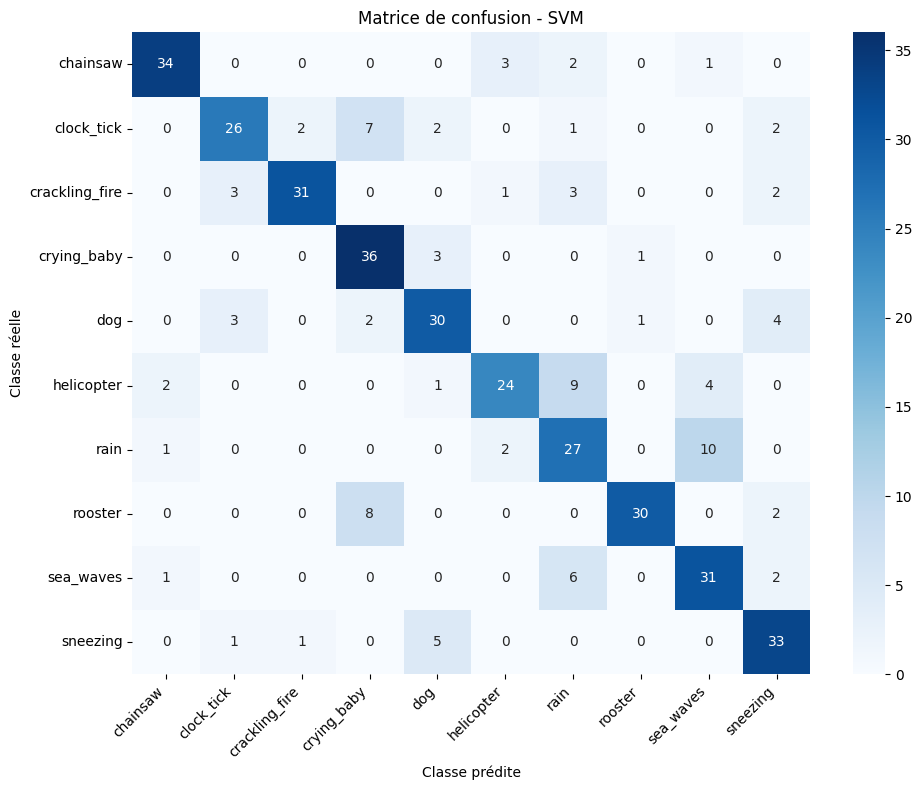

In [13]:
#Matrice de confusion
labels = sorted(np.unique(y_labels))
cm = confusion_matrix(all_true, all_pred, labels=labels)
plt.figure(figsize=(10, 8))
sns.heatmap(
 cm, annot=True, fmt="d",
 xticklabels=labels,
 yticklabels=labels,
 cmap="Blues"
)
plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.title("Matrice de confusion - SVM")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [14]:
#Fonction Mel
N_MELS = 128
N_FFT = 2048
HOP_LENGTH = 512
def extract_mel(y, sr=TARGET_SR):
 mel = librosa.feature.melspectrogram(
 y=y,
 sr=sr,
 n_fft=N_FFT,
 hop_length=HOP_LENGTH,
 n_mels=N_MELS
 )
 mel_db = librosa.power_to_db(mel, ref=np.max)
 # Mise à l'échelle simple vers [0, 1]
 mel_db = (mel_db + 80.0) / 80.0
 mel_db = np.clip(mel_db, 0.0, 1.0)
 return mel_db.astype(np.float32)

In [15]:
#Construire X pour le CNN
X_mel = []
for _, row in metadata_10.iterrows():
 file_path = os.path.join(AUDIO_PATH, row["filename"])
 audio = load_and_preprocess(file_path)
 X_mel.append(extract_mel(audio))
X_mel = np.array(X_mel)[..., np.newaxis]
print("Forme des données CNN :", X_mel.shape)

Forme des données CNN : (400, 128, 216, 1)


In [16]:
 #Encoder les catégories
from sklearn.preprocessing import LabelEncoder
from tensorflow import keras
from tensorflow.keras import layers
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y_labels)
num_classes = len(label_encoder.classes_)
y_onehot = keras.utils.to_categorical(
 y_encoded, num_classes=num_classes)

In [17]:
# Définir un CNN léger
def build_cnn(input_shape, num_classes):
    model = keras.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv2D(16, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.4),
        layers.Dense(num_classes, activation="softmax")
    ])
    model.compile(
        optimizer="adam",
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

In [18]:
 #Validation croisée correcte du CNN
from sklearn.metrics import accuracy_score
cnn_true = []
cnn_pred = []
for test_fold in sorted(np.unique(folds)):
  train_idx = folds != test_fold
 test_idx = folds == test_fold
 cnn = build_cnn(X_mel.shape[1:], num_classes)
 cnn.fit(
 X_mel[train_idx],
 y_onehot[train_idx],
 epochs=20,
 batch_size=16,
 validation_split=0.15,
 verbose=0,
 callbacks=[
 keras.callbacks.EarlyStopping(
 patience=4,
 restore_best_weights=True
 )
 ]
 )
 probabilities = cnn.predict(X_mel[test_idx], verbose=0)
 predictions = np.argmax(probabilities, axis=1)
 cnn_true.extend(y_encoded[test_idx])
 cnn_pred.extend(predictions)
print("CNN accuracy :", accuracy_score(cnn_true, cnn_pred))

CNN accuracy : 0.6375


In [19]:
#Comparer les résultats

svm_accuracy = accuracy_score(all_true, all_pred)
cnn_accuracy = accuracy_score(cnn_true, cnn_pred)
print(f"SVM : {svm_accuracy:.3f}")
print(f"CNN : {cnn_accuracy:.3f}")

SVM : 0.755
CNN : 0.637


In [20]:
#Entraîner les modèles finaux sur toutes les données
# SVM final
svm_final = clone(svm_template)
svm_final.fit(X_mfcc, y_labels)
joblib.dump(svm_final, "svm_sound_classifier.joblib")
# CNN final
cnn_final = build_cnn(X_mel.shape[1:], num_classes)
cnn_final.fit(
 X_mel, y_onehot,
 epochs=20,
 batch_size=16,
 validation_split=0.1,
 verbose=1
)
cnn_final.save("cnn_sound_classifier.keras")
# Sauvegarder l'ordre des classes
joblib.dump(label_encoder, "label_encoder.joblib")
print("Modèles sauvegardés.")


Epoch 1/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 9s 293ms/step - accuracy: 0.2306 - loss: 2.0976 - val_accuracy: 0.2500 - val_loss: 1.8270
Epoch 2/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 6s 264ms/step - accuracy: 0.4389 - loss: 1.4998 - val_accuracy: 0.5250 - val_loss: 1.3837
Epoch 3/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 10s 240ms/step - accuracy: 0.6194 - loss: 1.0875 - val_accuracy: 0.5250 - val_loss: 1.2755
Epoch 4/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 11s 263ms/step - accuracy: 0.6083 - loss: 1.0277 - val_accuracy: 0.5500 - val_loss: 1.2751
Epoch 5/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 7s 300ms/step - accuracy: 0.7417 - loss: 0.7709 - val_accuracy: 0.6500 - val_loss: 1.1781
Epoch 6/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 10s 270ms/step - accuracy: 0.7583 - loss: 0.6415 - val_accuracy: 0.7250 - val_loss: 0.8663
Epoch 7/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 10s 237ms/step - accuracy: 0.8111 - loss: 0.5213 - val_accuracy: 0.7250 - val_loss: 0.8759
Epoch 8/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 6s 262ms/step - accuracy: 0.8389 - loss: 0.4801 - val_accuracy

APPLICATION GRADIO

In [21]:
#Charger les modèles
import gradio as gr
import joblib
import numpy as np
import librosa
import matplotlib.pyplot as plt
svm_model = joblib.load("svm_sound_classifier.joblib")
cnn_model = keras.models.load_model("cnn_sound_classifier.keras")
label_encoder = joblib.load("label_encoder.joblib")


In [22]:
# Fonction de prédiction SVM ou CNN
def predict_audio(file_path, model_choice):
    if file_path is None:
        return "Veuillez importer un fichier audio.", None, None

    y = load_and_preprocess(file_path)

    if model_choice == "SVM":
        features = extract_mfcc_features(y).reshape(1, -1)
        probabilities = svm_model.predict_proba(features)[0]
        classes = svm_model.classes_
        scores = {
            str(label): float(score)
            for label, score in zip(classes, probabilities)
        }
    else:
        mel = extract_mel(y)
        x = mel[np.newaxis, ..., np.newaxis]
        probabilities = cnn_model.predict(x, verbose=0)[0]
        scores = {
            str(label): float(score)
            for label, score in zip(label_encoder.classes_, probabilities)
        }

    predicted_class = max(scores, key=scores.get)
    confidence = scores[predicted_class]

    result = (
        f"Classe prédite : {predicted_class}\n"
        f"Score du modèle : {confidence:.1%}"
    )

    # Tracer la forme d'onde
    fig, ax = plt.subplots(figsize=(9, 2.5))
    librosa.display.waveshow(y, sr=TARGET_SR, ax=ax)
    ax.set_title("Forme d'onde")
    ax.set_xlabel("Temps (s)")
    ax.set_ylabel("Amplitude")
    fig.tight_layout()

    return result, scores, fig

In [23]:
# Créer l'interface
with gr.Blocks(theme=gr.themes.Soft()) as app:
    gr.Markdown(
        "# SoundAI - Classification des sons\n"
        "Importez un son pour reconnaître sa catégorie."
    )

    with gr.Row():
        with gr.Column():
            audio_input = gr.Audio(
                sources=["upload"],
                type="filepath",
                label="Fichier audio"
            )
            model_choice = gr.Radio(
                ["SVM", "CNN"],
                value="SVM",
                label="Modèle"
            )
            analyze_button = gr.Button(
                "Analyser le son",
                variant="primary"
            )

        with gr.Column():
            prediction = gr.Textbox(
                label="Résultat"
            )
            scores = gr.Label(
                label="Scores par catégorie",
                num_top_classes=5
            )
            waveform = gr.Plot(
                label="Forme d'onde"
            )

    analyze_button.click(
        fn=predict_audio,
        inputs=[audio_input, model_choice],
        outputs=[prediction, scores, waveform]
    )

app.launch(share=True)

/tmp/ipykernel_8161/3139422002.py:2: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as app:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://a914abd5ed334aaa31.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
